In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

## load data

In [2]:
# get matched subreddits
input_fpath = f"{DATAPATH}/data/samples"
X0 = 10; N0 = 1
X1 = 20; N1 = 10
X2 = "inf"; N2 = 1
covs1 = "lifetime_d"
covs2 = "lifetime_d_n_post_author_till2019_log"
matched1_indp_df = pd.read_csv(f"{input_fpath}/cem-batch4-new/matched_table_banned_3274_cem_X{X0}N{N0}_{covs1}.csv")
matched2_indp_df = pd.read_csv(f"{input_fpath}/cem-batch4-new/matched_table_banned_3274_cem_X{X1}N{N1}_{covs2}.csv")
matched2_conn_df = pd.read_csv(f"{input_fpath}/cem-batch4-new/matched_table_banned_3274_cem_X{X2}N{N2}_{covs2}.csv")

# get banned subreddits and random samples
samples_df = pd.read_csv(f"{DATAPATH}/data/samples/to_match_table_selfid_banned_3274_260528.csv")
samples_df = samples_df[samples_df["lifetime_d"]>0]

banned_df = samples_df[samples_df["if_banned"]==1]
random_df = samples_df[samples_df["if_banned"]==0].sample(n=len(banned_df), replace=False, random_state=42)

# banned_random_df = pd.concat([banned_df, random_df])
# banned_random_df.to_csv(f"{DATAPATH}/data/samples/sample_banned_random_3274_250629.csv", index=False)

matched1_indp = set(matched1_indp_df[matched1_indp_df["if_banned"]==0]["subreddit"].tolist())
matched2_indp = set(matched2_indp_df[matched2_indp_df["if_banned"]==0]["subreddit"].tolist())
matched2_conn = set(matched2_conn_df[matched2_conn_df["if_banned"]==0]["subreddit"].tolist())
random = set(random_df["subreddit"].tolist())
banned = set(banned_df["subreddit"].tolist())
print(len(matched1_indp), len(matched2_indp), len(matched2_conn), len(random), len(banned))

3274 3274 3274 3274 3274


In [3]:
subreddit_sets = {
    "banned": banned,
    "matched1_indp": matched1_indp,
    "matched2_indp": matched2_indp, 
    "matched2_conn": matched2_conn,
    "random": random, 
}

In [4]:
df_all = pd.concat([matched1_indp_df, matched2_indp_df, matched2_conn_df, random_df, banned_df], axis=0)
df_all = df_all[df_all["subreddit"].isin(matched1_indp.union(matched2_indp).union(matched2_conn).union(random).union(banned))]
df_all = df_all.drop_duplicates(subset=["subreddit"])
count2019 = pd.read_parquet(f"{DATAPATH}/data/counts-raw/count_joint_n_item_n_author_minmax_utc_2019.parquet")
df_all = df_all.merge(
    count2019[["subreddit", "n_subm", "n_comm"]], 
    on="subreddit", 
    how="left").fillna(0).rename(columns={"n_subm":"n_subm2019", "n_comm":"n_comm2019"})
df_all.head()
df_all["n_subm2019_log"] = np.log1p(df_all["n_subm2019"])
df_all["n_comm2019_log"] = np.log1p(df_all["n_comm2019"])
df_all["n_subm_till2019_log"] = np.log1p(df_all["n_subm_till2019"])
df_all["n_comm_till2019_log"] = np.log1p(df_all["n_comm_till2019"])

## subreddit-level comparisons

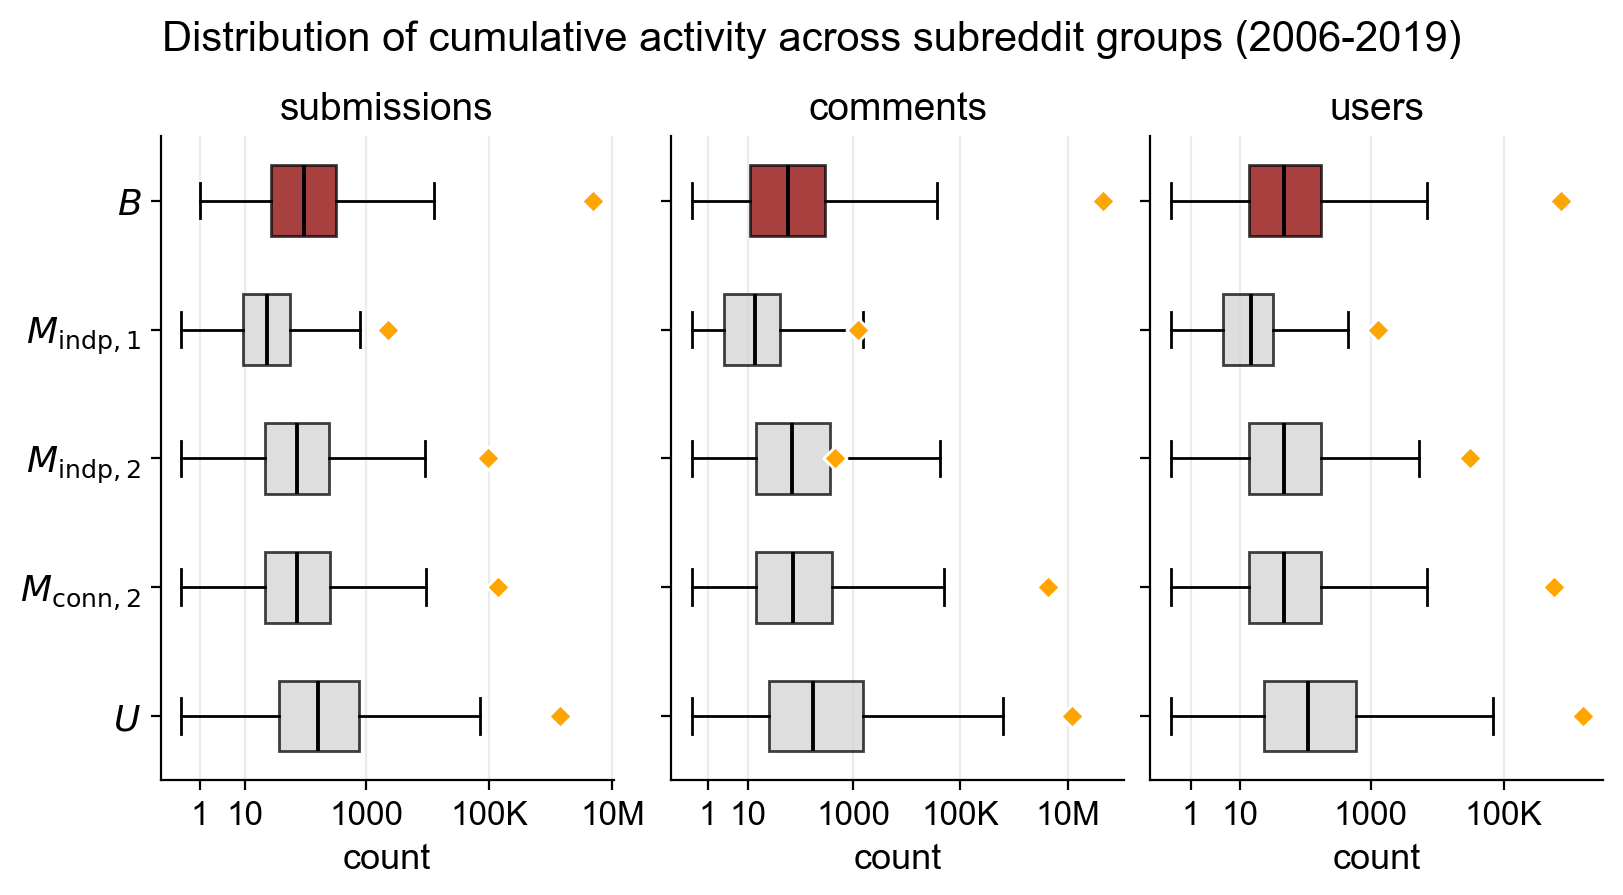

In [ ]:
from matplotlib.ticker import FuncFormatter
from src.utils.plot_helper import set_log1p_count_axis, log1p_count_formatter

covs = ["n_subm_till2019_log", "n_comm_till2019_log", "n_post_author_till2019_log"]
group_names = [r"$B$", r"$M_{\mathrm{indp},1}$", r"$M_{\mathrm{indp},2}$", r"$M_{\mathrm{conn},2}$", r"$U$"]
groups = [banned, matched1_indp, matched2_indp, matched2_conn, random]

highlight = {
    "the_donald": 0,          # B
    "portykong": 1,
    "url": 2,
    "insanepeoplefacebook": 3,
    "explainlikeimfive": 4,   # U
}

fig, axes = plt.subplots(
    nrows=1, 
    ncols=len(covs), 
    figsize=(8,4), 
    sharey=True, 
    constrained_layout=True
)

positions = list(range(len(groups)))[::-1]  # banned on top

for i, cov in enumerate(covs):

    data = [
        df_all.loc[df_all["subreddit"].isin(grp), cov].dropna().values
        for grp in groups
    ]

    bp = axes[i].boxplot(
        data,
        vert=False,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        showfliers=False,   # usually cleaner for heavy-tailed subreddit vars
        medianprops=dict(color="black", linewidth=1.4),
        boxprops=dict(edgecolor="black", linewidth=1),
        whiskerprops=dict(color="black", linewidth=1),
        capprops=dict(color="black", linewidth=1),
    )

    for j, box in enumerate(bp["boxes"]):
        box.set_facecolor("darkred" if j == 0 else "lightgrey")
        box.set_alpha(0.75)

    # overlay selected subreddits
    for subreddit, group_idx in highlight.items():

        row = df_all.loc[df_all["subreddit"] == subreddit]

        if len(row) == 0 or pd.isna(row[cov].iloc[0]):
            continue

        x = row[cov].iloc[0]
        y = positions[group_idx]

        axes[i].scatter(
            x, y,
            s=35,
            marker="D",
            facecolor="orange",
            edgecolor="white",
            linewidth=1,
            zorder=5,
        )

        # axes[i].annotate(
        #     f"r/{subreddit}",
        #     (x, y),
        #     xytext=(0, 8),
        #     textcoords="offset points",
        #     ha="center",
        #     va="bottom",
        #     fontsize=8,
        # )

    axes[i].grid(axis="x", alpha=0.25)

axes[0].set_yticks(positions)
axes[0].set_yticklabels(group_names, fontsize=13, fontfamily="monospace")

axes[0].set_title("submissions", fontsize=14)
axes[1].set_title("comments", fontsize=14)
axes[2].set_title("users", fontsize=14)

axes[0].set_xlabel("count", fontsize=13)
axes[1].set_xlabel("count", fontsize=13)
axes[2].set_xlabel("count", fontsize=13)

# Only use this if your variables are log10-transformed counts
for ax in axes:
    set_log1p_count_axis(ax)

fig.suptitle("Distribution of cumulative activity across subreddit groups (2006-2019)", fontsize=15, y=1.08)
# plt.savefig("../../output/appendix/activity-distribution-5groups-boxplots.pdf", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/appendix/activity-distribution-5groups-boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
def format_count(x):
    if x >= 1_000_000:
        return f"{x / 1_000_000:.1f}M"
    elif x >= 1_000:
        return f"{x / 1_000:.0f}K"
    else:
        return f"{x:.0f}"

In [7]:
subreddit_sets = [matched1_indp, matched2_indp, matched2_conn, random, banned]
sets_label = ["matched1_indp", "matched2_indp", "matched2_conn", "random", "banned"]
rank_table = pd.DataFrame()
top_subrs = {}
for i, s in enumerate(subreddit_sets):
    # print(len(df_all[df_all["subreddit"].isin(s)]))
    print(sets_label[i])
    df_all_sub = df_all[df_all["subreddit"].isin(s)].sort_values(by="n_post_author_till2019", ascending=False)
    # print(df_all_sub[["subreddit", "n_post_author_till2019"]].head(10))
    rank_table[f"top20_sub_{sets_label[i]}"] = df_all_sub["subreddit"].head(20).tolist()
    top_subrs[sets_label[i]] = df_all_sub["subreddit"].head(10).tolist()

matched1_indp
matched2_indp
matched2_conn
random
banned


In [8]:
# quick check: the percentage of one subreddit's activity in the total activity of a subreddit set
grp = random
grp_label = "random"
# cov = "n_post_author_till2019"
# cov = "n_subm_till2019"
cov = "n_comm_till2019"
sub = "explainlikeimfive"
# sub = "the_donald"
totals = df_all.loc[df_all["subreddit"].isin(grp), cov].fillna(0).sum()
# total_top = df_all.loc[df_all["subreddit"]==sub, cov].fillna(0).sum()
total_top = df_all.loc[df_all["subreddit"].isin(top_subrs[grp_label]), cov].fillna(0).sum()
total_top/totals

0.43794367484359314

In [9]:
user_count = pd.read_parquet(f"{DATAPATH}/data/counts-raw/subreddit_set_user_counts_2005_2019.parquet")
user_count = user_count[user_count["year"]==2019]
print(user_count)
cov = "n_cumulative_users_post"
group_names2 = ["banned", "matched1_indp", "matched2_indp", "matched2_conn", "random"]
totals = [
    user_count.loc[user_count["set"]==grp, cov].values[0]
    for grp in group_names2]
totals

              set  year  n_new_users_subm  n_cumulative_users_subm  \
14         banned  2019            227358                   671557   
29  matched1_indp  2019             27223                    53754   
44  matched2_conn  2019            248707                   573946   
59  matched2_indp  2019            174815                   425681   
74         random  2019           1113695                  3814172   

    n_new_users_comm  n_cumulative_users_comm  n_new_users_post  \
14            514825                  1397202            609856   
29             28702                    45525             45426   
44            692326                  1479832            777648   
59            209250                   381828            307694   
74           1965773                  6710906           2265461   

    n_cumulative_users_post  
14                  1690192  
29                    81803  
44                  1692358  
59                   666452  
74                  781726

[1690192, 81803, 666452, 1692358, 7817269]

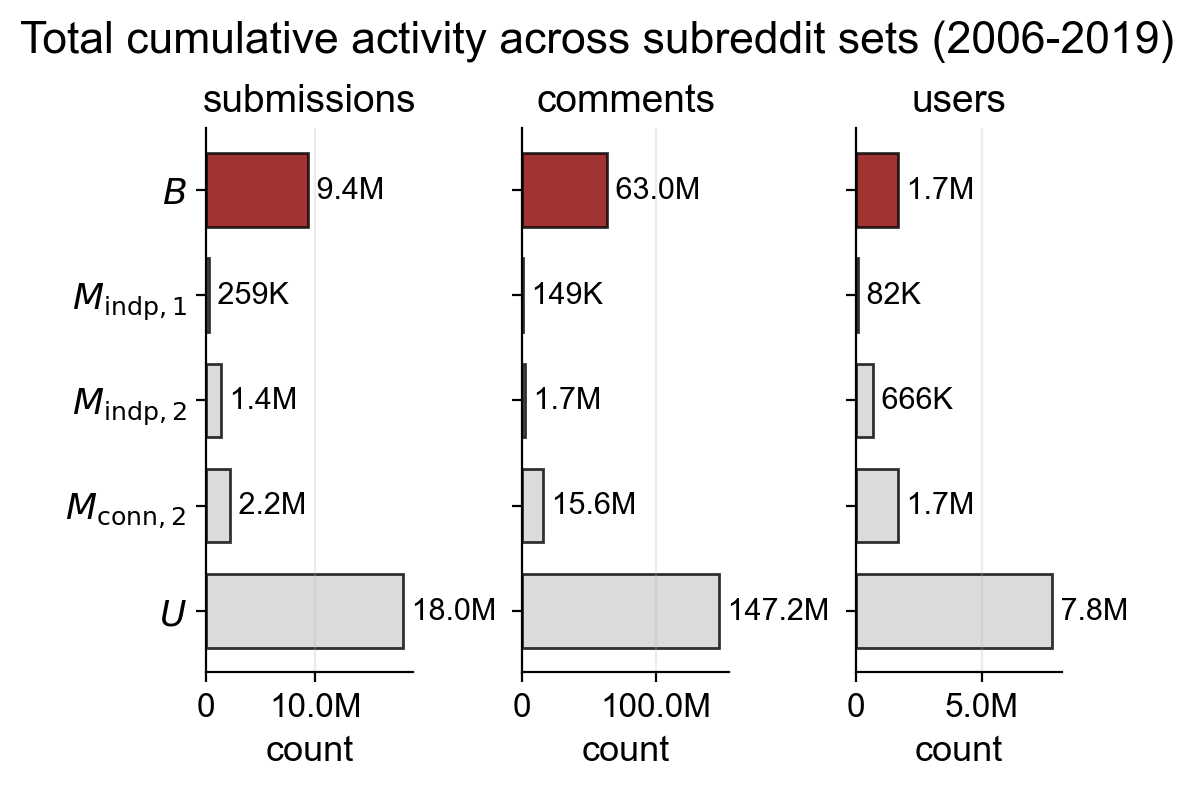

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
# from src.utils.plot_helper import _compact_count_label

covs = ["n_subm_till2019", "n_comm_till2019", "n_cumulative_users_post"]
group_names = [r"$B$", r"$M_{\mathrm{indp},1}$", r"$M_{\mathrm{indp},2}$", r"$M_{\mathrm{conn},2}$", r"$U$"]
group_names2 = ["banned", "matched1_indp", "matched2_indp", "matched2_conn", "random"]
groups = [banned, matched1_indp, matched2_indp, matched2_conn, random]

user_count = pd.read_parquet(f"{DATAPATH}/data/counts-raw/subreddit_set_user_counts_2005_2019.parquet")
user_count = user_count[user_count["year"]==2019]

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(5.4,3.5),
    sharey=True,
    constrained_layout=True
)

positions = list(range(len(groups)))[::-1]  # banned on top

for i, cov in enumerate(covs):

    if i == 2: 
        totals = [
            user_count.loc[user_count["set"]==grp, cov].values[0]
            for grp in group_names2
        ]
    else:
        totals = [
            df_all.loc[df_all["subreddit"].isin(grp), cov].fillna(0).sum()
            for grp in groups
        ]

    axes[i].barh(
        positions,
        totals,
        color=["darkred"] + ["lightgrey"] * (len(groups) - 1),
        edgecolor="black",
        alpha=0.8,
        height=0.7,
    )

    axes[i].grid(axis="x", alpha=0.25)

    # optional: add value labels
    for pos, total in zip(positions, totals):
        axes[i].text(
            total,
            pos,
            f" {format_count(total)}",
            va="center",
            ha="left",
            fontsize=11
        )

axes[0].set_yticks(positions)
axes[0].set_yticklabels(group_names, fontsize=13, fontfamily="monospace")

axes[0].set_title("submissions", fontsize=14)
axes[1].set_title("comments", fontsize=14)
axes[2].set_title("users", fontsize=14)

axes[0].set_xlabel("count", fontsize=13)
axes[1].set_xlabel("count", fontsize=13)
axes[2].set_xlabel("count", fontsize=13)

for ax in axes:
    ax.xaxis.set_major_formatter(
        FuncFormatter(
            lambda x, pos: (
                "0" if x == 0
                else f"{x/1e6:.1f}M" if x >= 1e6
                else f"{x/1e3:.0f}K"
            )
        )
    )

fig.suptitle("Total cumulative activity across subreddit sets (2006-2019)", fontsize=16, y=1.08)
# plt.savefig("../../output/mainbody/activity-total-5groups-barcharts.pdf", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/mainbody/activity-total-5groups-barcharts.png", dpi=300, bbox_inches="tight")

plt.show()

/tmp/ipykernel_1057610/2172721720.py:54: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


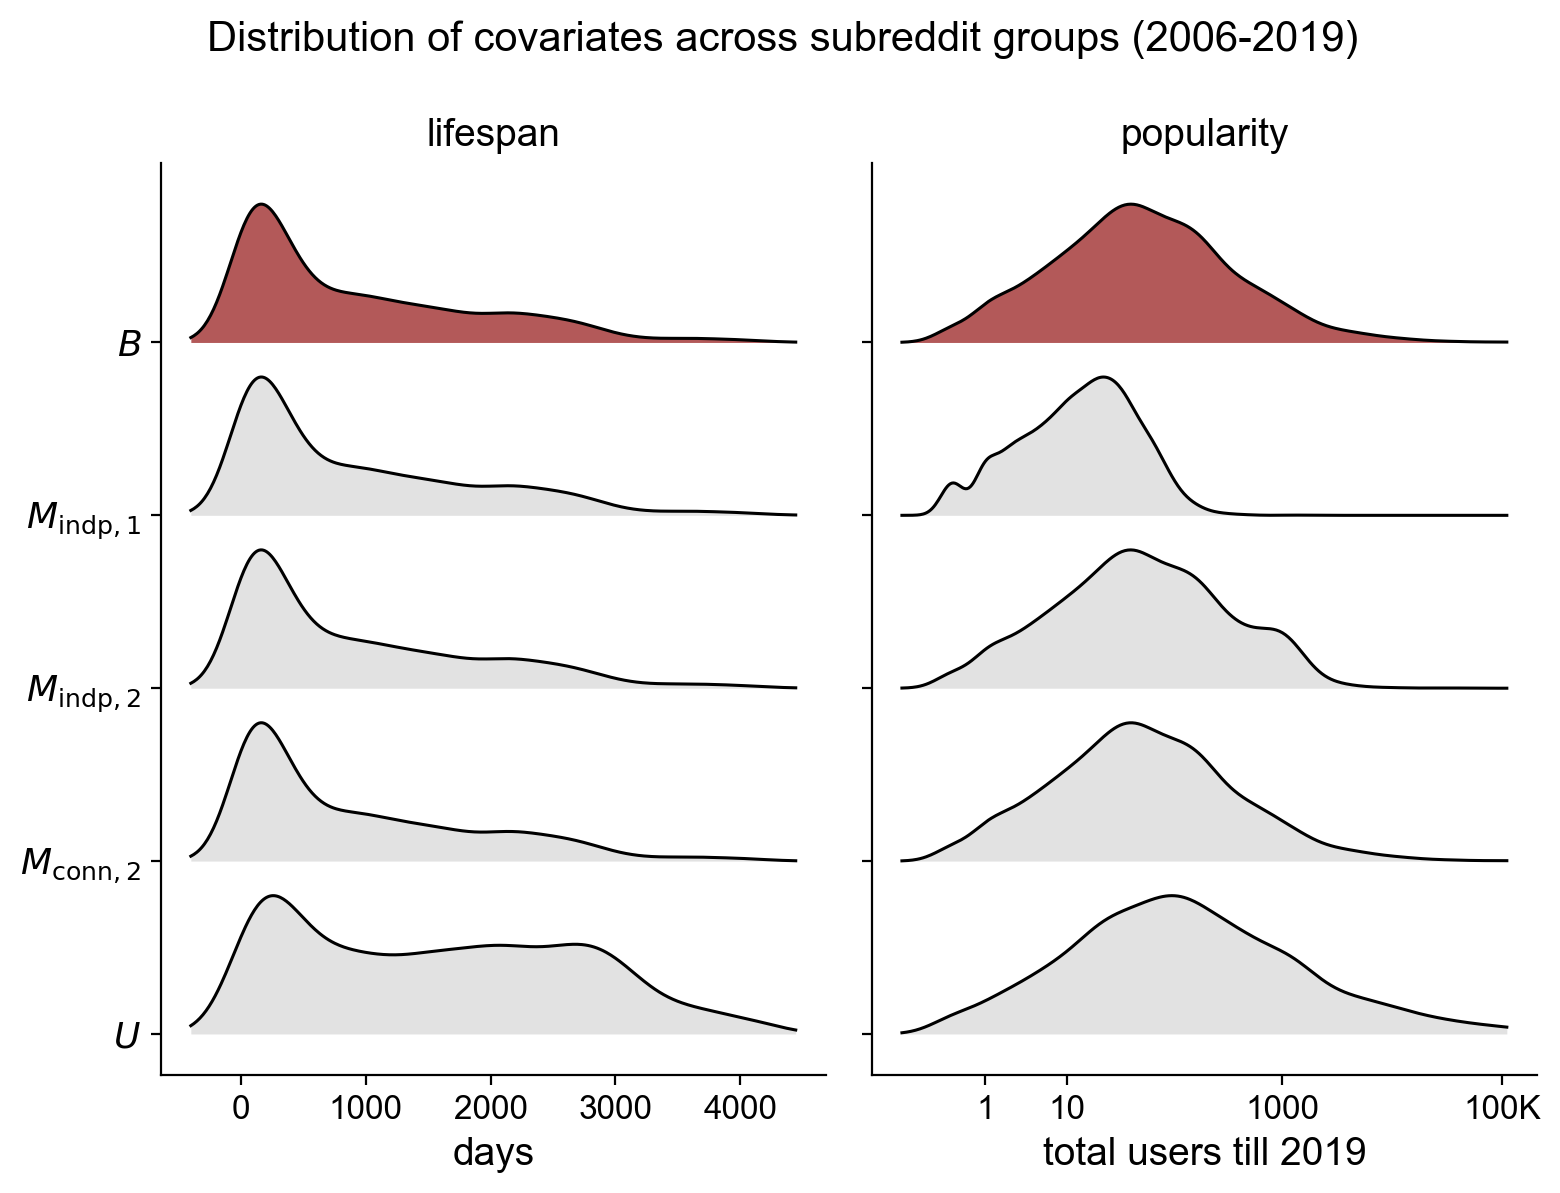

In [11]:
from scipy.stats import gaussian_kde

covs = ["lifetime_d", "n_post_author_till2019_log"]
# group_names = ["BANNED", "MATCH-INDP-1COV", "MATCH-INDP-2COV", "MATCH-CONN-2COV", "RANDOM"]
group_names = [r"$B$", r"$M_{\mathrm{indp},1}$", r"$M_{\mathrm{indp},2}$", r"$M_{\mathrm{conn},2}$", r"$U$"]
groups = [banned, matched1_indp, matched2_indp, matched2_conn, random]
bandwidth_adjust = 1
ridge_scale = 0.8
fig, axes = plt.subplots(nrows=1, ncols=len(covs), figsize=(8,6), sharey=True, constrained_layout=True)

for i,cov in enumerate(covs):
    xmin = df_all[cov].quantile(0.005)
    xmax = df_all[cov].quantile(0.995)
    pad = (xmax - xmin) * 0.1 if xmax > xmin else 1
    x_grid = np.linspace(xmin - pad, xmax + pad, 400)

    for j, grp in enumerate(groups):

        vals = df_all[df_all["subreddit"].isin(grp)][cov].values

        kde = gaussian_kde(vals)
        kde.set_bandwidth(kde.factor * bandwidth_adjust)

        density = kde(x_grid)
        density = density / density.max() * ridge_scale

        y_base = len(groups) - 1 - j

        axes[i].fill_between(
            x_grid,
            y_base,
            y_base + density,
            alpha=0.65,
            linewidth=0,
            color= "darkred" if j == 0 else "lightgrey", 
        )

        axes[i].plot(
            x_grid,
            y_base + density,
            color="black",
            linewidth=1.1,
        )
axes[0].set_title("lifespan", fontsize=14)
axes[1].set_title("popularity", fontsize=14)
axes[1].set_xlabel("total users till 2019", fontsize=14)
# axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{int(x)}}}$"))
# EDIT: `n_post_author_till2019_log` is log1p/natural-log scale; label ticks as original counts.
set_log1p_count_axis(axes[1])
axes[0].set_xlabel("days", fontsize=14)
axes[0].set_yticks(range(len(groups)))
axes[0].set_yticklabels(list(reversed(group_names)), fontsize=13, fontfamily="monospace")
fig.suptitle("Distribution of covariates across subreddit groups (2006-2019)", fontsize=15, y=0.99)
plt.tight_layout()
# plt.savefig("../../output/appendix/matching-cov-distribution-5groups-2covs.pdf", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/appendix/matching-cov-distribution-5groups-2covs.png", dpi=300, bbox_inches="tight")
    

## user-level comparisons

In [12]:
count_dir = f"{DATAPATH}/data/counts-raw"
count_df_subm = pl.scan_parquet(f"{count_dir}/author_subreddit_count_submissions_minmax_utc_*.parquet").collect()
count_df_comm = pl.scan_parquet(f"{count_dir}/author_subreddit_count_comments_minmax_utc_*.parquet").collect()
count_df_subm = count_df_subm.filter(pl.col("year")<=2019)
count_df_comm = count_df_comm.filter(pl.col("year")<=2019)

subrs_focal = set(df_all["subreddit"].tolist())
author_focal = set(count_df_subm.filter(pl.col("subreddit").is_in(subrs_focal))["author"].unique())
author_focal |= set(count_df_comm.filter(pl.col("subreddit").is_in(subrs_focal))["author"].unique())

In [13]:
# Subreddit to group matching
group_map = pl.concat(
    [
        pl.DataFrame({"subreddit": list(grp), "group": gname,})
        for gname, grp in zip(group_names, groups)
    ],
    how="vertical"
).unique()

# OPTIONAL check: if a subreddit belongs to multiple groups
dup_subrs = (
    group_map
    .group_by("subreddit")
    .agg(pl.col("group").n_unique().alias("n_groups"))
    .filter(pl.col("n_groups") > 1)
)

print("Subreddits appearing in multiple groups:", dup_subrs.height)

# Restrict count data to subreddits in the five groups
count_subm_grouped = count_df_subm.join(group_map, on="subreddit", how="inner")
count_comm_grouped = count_df_comm.join(group_map, on="subreddit", how="inner")

Subreddits appearing in multiple groups: 2520


In [14]:
# aggregate submissions and comments within each group-author pair
aggr_user_subm_grouped = (count_subm_grouped
    .group_by(["group", "author"])
    .agg(
        pl.col("n_subm").sum().alias("total_subm"),
        pl.col("min_utc").min().alias("first_utc_subm"),
        pl.col("max_utc").max().alias("last_utc_subm"),
    )
)

aggr_user_comm_grouped = (count_comm_grouped
    .group_by(["group", "author"])
    .agg(
        pl.col("n_comm").sum().alias("total_comm"),
        pl.col("min_utc").min().alias("first_utc_comm"),
        pl.col("max_utc").max().alias("last_utc_comm"),
    )
)

# compute number of distinct subreddits each author used 
# within each group, using submissions + comments together

n_subr_grouped = (
    pl.concat(
        [
            count_subm_grouped.select(["group", "author", "subreddit"]),
            count_comm_grouped.select(["group", "author", "subreddit"]),
        ],
        how="vertical"
    )
    .unique()
    .group_by(["group", "author"])
    .agg(
        pl.col("subreddit").n_unique().alias("n_subr")
    )
)

In [15]:
# combine into one group-author-level dataframe
na_authors = ["[deleted]"]
user_group_df = (
    aggr_user_subm_grouped
    .join(
        aggr_user_comm_grouped,
        on=["group", "author"],
        how="full",
        coalesce=True,
    )
    .join(
        n_subr_grouped,
        on=["group", "author"],
        how="left",
    )
    .with_columns(
        pl.col("total_subm").fill_null(0),
        pl.col("total_comm").fill_null(0),
        pl.col("n_subr").fill_null(0),
    )
    .with_columns(
        pl.col("total_subm").log1p().alias("total_subm_log"),
        pl.col("total_comm").log1p().alias("total_comm_log"),
        pl.min_horizontal("first_utc_subm", "first_utc_comm").alias("first_utc"),
        pl.max_horizontal("last_utc_subm", "last_utc_comm").alias("last_utc"),
    )
    .with_columns(
        (pl.col("last_utc") - pl.col("first_utc"))
        .dt.total_days()
        .alias("lifetime_d")
    )
    .filter(~pl.col("author").is_in(na_authors))
)

user_group_df.head()

group,author,total_subm,first_utc_subm,last_utc_subm,total_comm,first_utc_comm,last_utc_comm,n_subr,total_subm_log,total_comm_log,first_utc,last_utc,lifetime_d
str,str,u32,datetime[ms],datetime[ms],u32,datetime[ms],datetime[ms],u32,f64,f64,datetime[ms],datetime[ms],i64
"""$U$""","""kingrazz0r""",0,null,null,2,2017-01-20 11:35:52,2017-03-05 21:37:22,2,0.0,1.098612,2017-01-20 11:35:52,2017-03-05 21:37:22,44
"""$U$""","""Poor_Quaterback""",0,null,null,1,2019-07-17 18:53:23,2019-07-17 18:53:23,1,0.0,0.693147,2019-07-17 18:53:23,2019-07-17 18:53:23,0
"""$B$""","""JuiceGoneWild""",0,null,null,3,2018-12-24 05:53:26,2018-12-24 06:30:20,1,0.0,1.386294,2018-12-24 05:53:26,2018-12-24 06:30:20,0
"""$B$""","""AndYetAnotherMichael""",0,null,null,1,2018-10-18 23:49:48,2018-10-18 23:49:48,1,0.0,0.693147,2018-10-18 23:49:48,2018-10-18 23:49:48,0
"""$U$""","""Saint-Peer""",1,2017-09-14 23:47:32,2017-09-14 23:47:32,33,2012-10-29 00:56:11,2019-12-18 03:13:52,9,0.693147,3.526361,2012-10-29 00:56:11,2019-12-18 03:13:52,2606


In [16]:
cov_specs = [
    {
        "cov": "lifetime_d",
        "filter": None,
        "title": "lifetime",
        "xlabel": "days active within each set\nsubmission/comment authors",
    },
    {
        "cov": "total_subm_log",
        "filter": pl.col("total_subm") > 0,
        "title": "submissions",
        "xlabel": "submissions within each set\nsubmission authors only",
    },
    {
        "cov": "total_comm_log",
        "filter": pl.col("total_comm") > 0,
        "title": "comments",
        "xlabel": "comments within each set\ncomment authors only",
    },
    # {
    #     "cov": "n_subr",
    #     "filter": None,
    #     "title": "subreddits",
    #     "xlabel": "subreddits within group\nsubmission/comment authors",
    # },
]

In [17]:
def set_log1p_count_axis2(ax):
    """Set clean count-scale ticks for an axis whose data are np.log1p(count)."""
    xmin, xmax = ax.get_xlim()
    max_count = max(1, np.expm1(xmax))
    nice_counts = np.array([1,2,5,10, 100,1_000, 100_000, 10_000_000, 1_000_000_000], dtype=float)
    ticks = np.log1p(nice_counts[nice_counts <= max_count * 1.05])
    ticks = ticks[ticks >= max(0, xmin) - 1e-9]
    if len(ticks) > 0:
        ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(FuncFormatter(log1p_count_formatter))

lifetime_d [1690192, 81803, 666452, 1692358, 7817269]
total_subm_log [671557, 53754, 425681, 573946, 3814172]
total_comm_log [1397202, 45525, 381828, 1479832, 6710906]


Text(0.5, 1.08, 'Distribution of user within-group activity levels for different subreddit groups (2006-2019)')

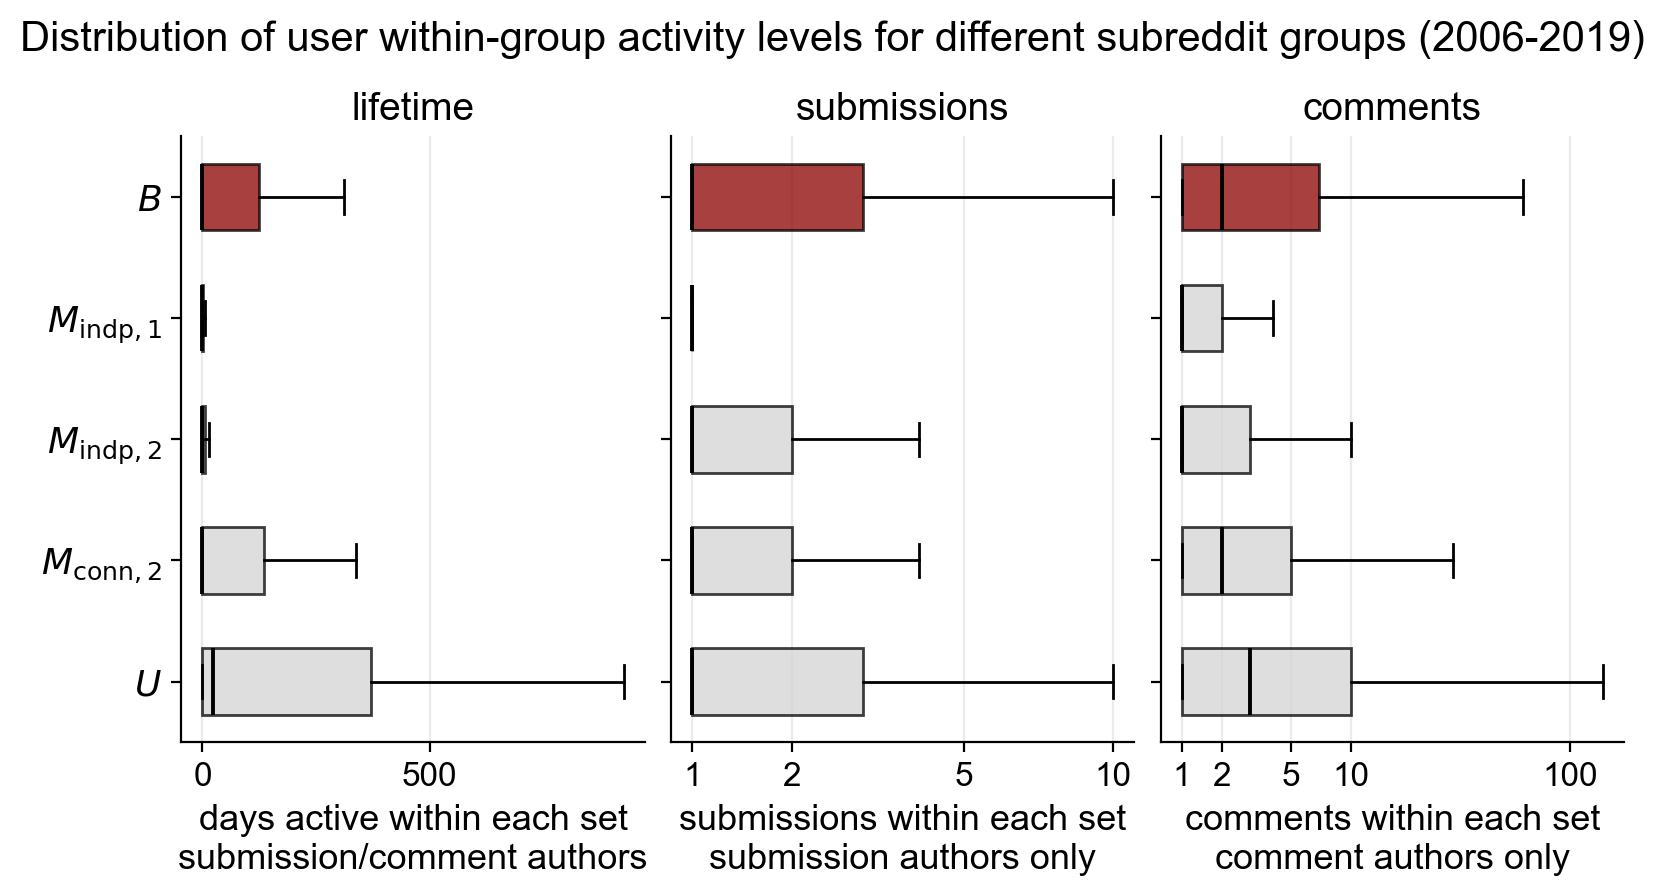

In [18]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(cov_specs),
    figsize=(8,4),
    sharey=True,
    constrained_layout=True,
)

positions = list(range(len(group_names)))[::-1]  # banned on top

for i, spec in enumerate(cov_specs):

    cov = spec["cov"]
    this_filter = spec["filter"]

    data = []

    for gname in group_names:
        this_df = user_group_df.filter(pl.col("group") == gname)

        if this_filter is not None:
            this_df = this_df.filter(this_filter)

        vals = (
            this_df
            .select(cov)
            .drop_nulls()
            .to_series()
            .to_numpy()
        )

        data.append(vals)

    print(cov, [len(d) for d in data])

    bp = axes[i].boxplot(
        data,
        vert=False,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(color="black", linewidth=1.4),
        boxprops=dict(edgecolor="black", linewidth=1),
        whiskerprops=dict(color="black", linewidth=1),
        capprops=dict(color="black", linewidth=1),
    )

    for j, box in enumerate(bp["boxes"]):
        box.set_facecolor("darkred" if j == 0 else "lightgrey")
        box.set_alpha(0.75)

    axes[i].set_title(spec["title"], fontsize=14)
    axes[i].set_xlabel(spec["xlabel"], fontsize=13)
    axes[i].grid(axis="x", alpha=0.25)

axes[0].set_yticks(positions)
axes[0].set_yticklabels(group_names, fontsize=13, fontfamily="monospace")

set_log1p_count_axis2(axes[1])
set_log1p_count_axis2(axes[2])

fig.suptitle("Distribution of user within-group activity levels for different subreddit groups (2006-2019)", fontsize=15, y=1.08)
# plt.savefig("../../output/appendix/user-activity-distribution-within-5groups-boxplots.pdf", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/appendix/user-activity-distribution-within-5groups-boxplots.png", dpi=300, bbox_inches="tight")

## survival analysis

In [19]:
# if min_utc/max_utc are epoch seconds; skip the from_epoch if already Datetime
cols = ["author","subreddit", "min_utc", "max_utc"]
count_df_post = pl.concat([
    count_df_subm.select(cols+["n_subm"]).rename({"n_subm":"n_posts"}), 
    count_df_comm.select(cols+["n_comm"]).rename({"n_comm":"n_posts"}), ], how="vertical")
count_df_post

count_df_post = count_df_post.with_columns([
    pl.from_epoch(pl.col("min_utc"), time_unit="ms").alias("min_utc"),
    pl.from_epoch(pl.col("max_utc"), time_unit="ms").alias("max_utc"),
])

BOT_AUTHORS = {"[deleted]", "AutoModerator"}
count_df_post = count_df_post.filter(
    ~pl.col("author").is_in(BOT_AUTHORS)
    # & ~pl.col("author").str.to_lowercase().str.ends_with("bot")   # optional heuristic
)

user_span_platform = count_df_post.group_by("author").agg(
    pl.col("min_utc").min().alias("first_utc"),
    pl.col("max_utc").max().alias("last_utc"),
)

In [20]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

TAU_DAYS  = 300                              # inactivity grace period
OBS_START = pd.Timestamp("2005-01-01")       # observation window start
OBS_END   = pd.Timestamp("2019-12-31")       # observation window end (data end)

# your 5 subreddit sets (each a list/set of subreddit names, lowercased consistently)
cohorts = {
    "banned":        banned,
    "matched1_indp": matched1_indp,
    "matched2_indp": matched2_indp,
    "matched2_conn": matched2_conn,
    "random":        random,
}

In [21]:
def build_survival_table(
    count_df,
    subr_set,
    scope="within",
    user_span_platform=None,
    tau_days=TAU_DAYS,
    obs_start=OBS_START,
    obs_end=OBS_END,
):

    in_cohort = count_df.filter(
        pl.col("subreddit").is_in(list(subr_set))
    )

    if scope == "within":
        span = in_cohort.group_by("author").agg(
            pl.col("min_utc").min().alias("first_utc"),
            pl.col("max_utc").max().alias("last_utc"),
        )

    elif scope == "platform":
        cohort_users = in_cohort.select("author").unique()

        span = user_span_platform.join(
            cohort_users,
            on="author",
            how="inner",
        )

    else:
        raise ValueError(scope)

    df = span.to_pandas()

    df["min_date"] = pd.to_datetime(
        df["first_utc"]
    ).dt.normalize()

    df["max_date"] = pd.to_datetime(
        df["last_utc"]
    ).dt.normalize()

    # ---------------------------------------------------------
    # FIXED ASCERTAINMENT CUTOFF
    # ---------------------------------------------------------
    #
    # The last tau_days of the dataset are used only to confirm
    # whether apparent exits before this cutoff are genuine.
    #
    ascertain_end = obs_end - pd.Timedelta(days=tau_days)

    # ---------------------------------------------------------
    # EVENT
    # ---------------------------------------------------------
    #
    # If the user's FINAL observed activity is on/before
    # ascertain_end, then we subsequently observe at least
    # tau_days with no return.
    #
    # -> confirmed exit
    #
    # If max_date is after ascertain_end:
    # -> exit cannot be confirmed within this design
    # -> right-censor at ascertain_end
    #
    df["event"] = (df["max_date"] <= ascertain_end).astype(int)

    # Keep same column as your original pipeline.
    # Only confirmed exits have an actual event time.
    df["event_time"] = df["max_date"].where(df["event"].eq(1), pd.NaT)

    # Confirmed event -> last activity
    # Censored user  -> common administrative cutoff
    df["stop_cal"] = df["max_date"].where(df["event"].eq(1), ascertain_end)
    # df["stop_cal"] = df["max_date"]

    # ---------------------------------------------------------
    # LEFT TRUNCATION / DELAYED ENTRY
    # this wouldn't happen if we set OBS_START in 2005/1/1
    # ---------------------------------------------------------

    df["entry_cal"] = df["min_date"].clip(lower=obs_start)
    df["tenure_entry"] = (df["entry_cal"] - df["min_date"]).dt.days
    df["tenure_exit"] = (df["stop_cal"] - df["min_date"]).dt.days + 1

    # Keep only users who actually overlap the analysis period.
    #
    # >= rather than > retains valid zero-duration events,
    # e.g. someone who contributes only once.
    df = df[df["tenure_exit"] > df["tenure_entry"]].reset_index(drop=True)

    return df

In [22]:
SCOPE = "within"   # or "platform"

kmfs, tables, summary_rows = {}, {}, []
for name, subrs in cohorts.items():
    t = build_survival_table(count_df_post, subrs, scope=SCOPE,
                             user_span_platform=user_span_platform)
    kmf = KaplanMeierFitter(label=name)
    kmf.fit(durations=t["tenure_exit"], event_observed=t["event"],
            entry=t["tenure_entry"])
    kmfs[name], tables[name] = kmf, t
    summary_rows.append({
        "cohort": name,
        "n_users": len(t),
        "n_events": int(t["event"].sum()),
        "pct_censored": 100 * (1 - t["event"].mean()),
        "median_survival_d": kmf.median_survival_time_,
        "surv_at_1y": float(kmf.predict(365)),
        "surv_at_2y": float(kmf.predict(730)),
    })

summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

       cohort  n_users  n_events  pct_censored  median_survival_d  surv_at_1y  surv_at_2y
       banned  1165674    968923     16.878733                4.0    0.213602    0.136323
matched1_indp    41788     38666      7.471044                1.0    0.072085    0.043741
matched2_indp   396469    368660      7.014168                1.0    0.068614    0.039205
matched2_conn  1037501    777840     25.027542                7.0    0.273706    0.190488
       random  5930737   4491308     24.270660               84.0    0.378014    0.288559


/tmp/ipykernel_1057610/1980496069.py:18: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 4000)


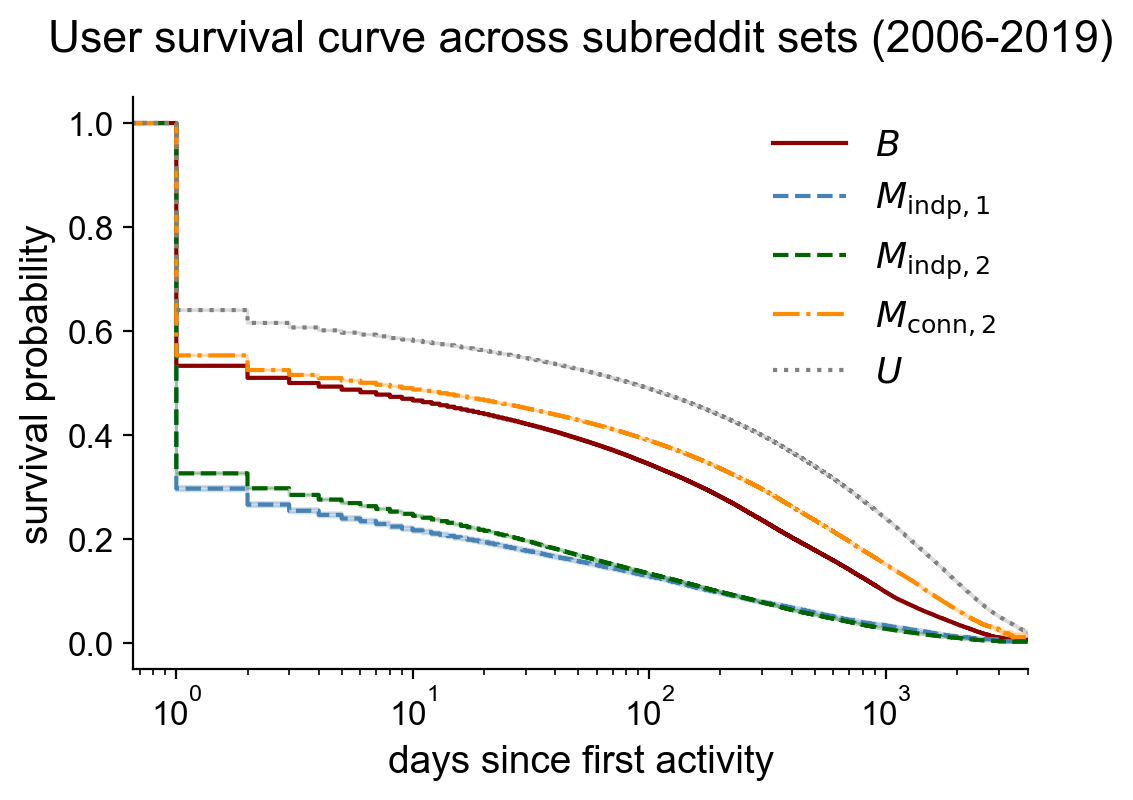

In [23]:
styles = {
    "banned":        dict(color="darkred",   linestyle="-", label=r"$B$"),
    "matched1_indp": dict(color="steelblue", linestyle="--", label=r"$M_{\mathrm{indp},1}$"),
    "matched2_indp": dict(color="darkgreen", linestyle="--", label=r"$M_{\mathrm{indp},2}$"),
    "matched2_conn": dict(color="darkorange",linestyle="-.", label=r"$M_{\mathrm{conn},2}$"),
    "random":        dict(color="grey",      linestyle=":", label=r"$U$"),
}

from matplotlib.ticker import FixedLocator, ScalarFormatter, NullFormatter, NullLocator

fig, ax = plt.subplots(figsize=(5.4,4.2))
for name, kmf in kmfs.items():
    kmf.plot_survival_function(ax=ax, ci_show=True, **styles[name])

ax.set_xlabel("days since first activity", fontsize=14)
ax.set_ylabel("survival probability", fontsize=14)
ax.set_xscale("log")
ax.set_xlim(0, 4000)
# ax.xaxis.set_major_locator(FixedLocator([120, 240, 360, 480, 720, 1440, 2880, 5760]))
# ax.xaxis.set_major_formatter(ScalarFormatter())   # plain numbers, not 10^3
# ax.xaxis.set_minor_locator(NullLocator())          # suppress unlabeled minor ticks

ax.legend(fontsize=13, frameon=False, loc=1)
ax.set_title(f"User survival curve across subreddit sets (2006-2019)", fontsize=16, y=1.05)
plt.tight_layout()
plt.savefig("../../output/mainbody/survival_curves_5sets.pdf", dpi=300, bbox_inches="tight")
plt.savefig("../../output/mainbody/survival_curves_5sets.png", dpi=300, bbox_inches="tight")

In [24]:
# sanity check
for name, t in tables.items():
    print(
        name,
        "max tenure_entry =", t["tenure_entry"].max(), # should be 0 
        "n left-truncated =", (t["tenure_entry"] > 0).sum(), # should be 0 if no left-truncation is implemented
        "min tenure_exit =", t["tenure_exit"].min(), # should be 0 if no left-truncation is implemented
    )

banned max tenure_entry = 0 n left-truncated = 0 min tenure_exit = 1
matched1_indp max tenure_entry = 0 n left-truncated = 0 min tenure_exit = 1
matched2_indp max tenure_entry = 0 n left-truncated = 0 min tenure_exit = 1
matched2_conn max tenure_entry = 0 n left-truncated = 0 min tenure_exit = 1
random max tenure_entry = 0 n left-truncated = 0 min tenure_exit = 1


In [25]:
# ---- one-time pre-aggregation over the full table ----
user_subr = count_df_post.group_by(["author", "subreddit"]).agg(
    pl.col("min_utc").min().alias("min_utc"),
    pl.col("max_utc").max().alias("max_utc"),
    pl.col("n_posts").sum().alias("n_posts"),
)

user_total = user_subr.group_by("author").agg(
    pl.col("n_posts").sum().alias("n_total"),
    pl.col("min_utc").min().alias("first_utc"),   # platform-wide span, free here
    pl.col("max_utc").max().alias("last_utc"),
)
user_span_platform = user_total.select(["author", "first_utc", "last_utc"])
# this might take about 3 mins

## robustness check: testing different `TAU_DAYS`

In [26]:
TAU_VALUES = [60, 120, 240, 360, 480, 720]

TAU_LABELS = {
    60:  "2 months",
    120: "4 months",
    240: "8 months",
    360: "12 months",
    480: "16 months",
    720: "24 months",
}

SCOPE = "within"

robustness_kmfs = {}
summary_rows = []

for tau in TAU_VALUES:
    print(f"TAU_DAYS = {tau} ({TAU_LABELS[tau]})")

    for name, subrs in cohorts.items():

        t = build_survival_table(
            count_df_post,
            subrs,
            scope=SCOPE,
            user_span_platform=user_span_platform,
            tau_days=tau,
            obs_start=OBS_START,
            obs_end=OBS_END,
        )

        kmf = KaplanMeierFitter(label=styles[name]["label"])

        kmf.fit(
            durations=t["tenure_exit"],
            event_observed=t["event"],
            entry=t["tenure_entry"],
        )

        robustness_kmfs[(tau, name)] = kmf

        summary_rows.append({
            "tau_days": tau,
            "tau_label": TAU_LABELS[tau],
            "ascertainment_end":
                OBS_END - pd.Timedelta(days=tau),
            "cohort": name,
            "n_users": len(t),
            "n_events": int(t["event"].sum()),
            "pct_censored":
                100 * (1 - t["event"].mean()),
            "median_survival_d":
                kmf.median_survival_time_,
            "surv_at_1y":
                float(kmf.predict(365)),
            "surv_at_2y":
                float(kmf.predict(730)),
        })

robustness_summary = pd.DataFrame(summary_rows)
robustness_summary = robustness_summary.sort_values(["tau_days", "cohort"]).reset_index(drop=True)
robustness_summary

TAU_DAYS = 60 (2 months)
TAU_DAYS = 120 (4 months)
TAU_DAYS = 240 (8 months)
TAU_DAYS = 360 (12 months)
TAU_DAYS = 480 (16 months)
TAU_DAYS = 720 (24 months)


,tau_days,tau_label,ascertainment_end,cohort,n_users,n_events,pct_censored,median_survival_d,surv_at_1y,surv_at_2y
0,60,2 months,2019-11-01,banned,1563114,1413431,9.575949,2.0,0.170377,0.096359
1,60,2 months,2019-11-01,matched1_indp,68946,65349,5.217126,1.0,0.051392,0.025416
2,60,2 months,2019-11-01,matched2_conn,1546716,1374865,11.110702,2.0,0.186167,0.095226
3,60,2 months,2019-11-01,matched2_indp,591202,564354,4.541257,1.0,0.051560,0.022878
4,60,2 months,2019-11-01,random,7464027,6595515,11.635971,40.0,0.305379,0.209101
5,120,4 months,2019-09-02,banned,1462657,1286514,12.042673,2.0,0.184425,0.108466
6,120,4 months,2019-09-02,matched1_indp,60072,56253,6.357371,1.0,0.061203,0.033011
7,120,4 months,2019-09-02,matched2_conn,1408467,1183183,15.994979,2.0,0.214889,0.123549
8,120,4 months,2019-09-02,matched2_indp,538088,507165,5.746830,1.0,0.058658,0.028346
9,120,4 months,2019-09-02,random,7085976,5903749,16.684039,52.0,0.331700,0.237335


/tmp/ipykernel_1057610/3076166958.py:25: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 4000)
/tmp/ipykernel_1057610/3076166958.py:25: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 4000)
/tmp/ipykernel_1057610/3076166958.py:25: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 4000)
/tmp/ipykernel_1057610/3076166958.py:25: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 4000)
/tmp/ipykernel_1057610/3076166958.py:25: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 4000)
/tmp/ipykernel_1057610/3076166958.py:25: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 4000)


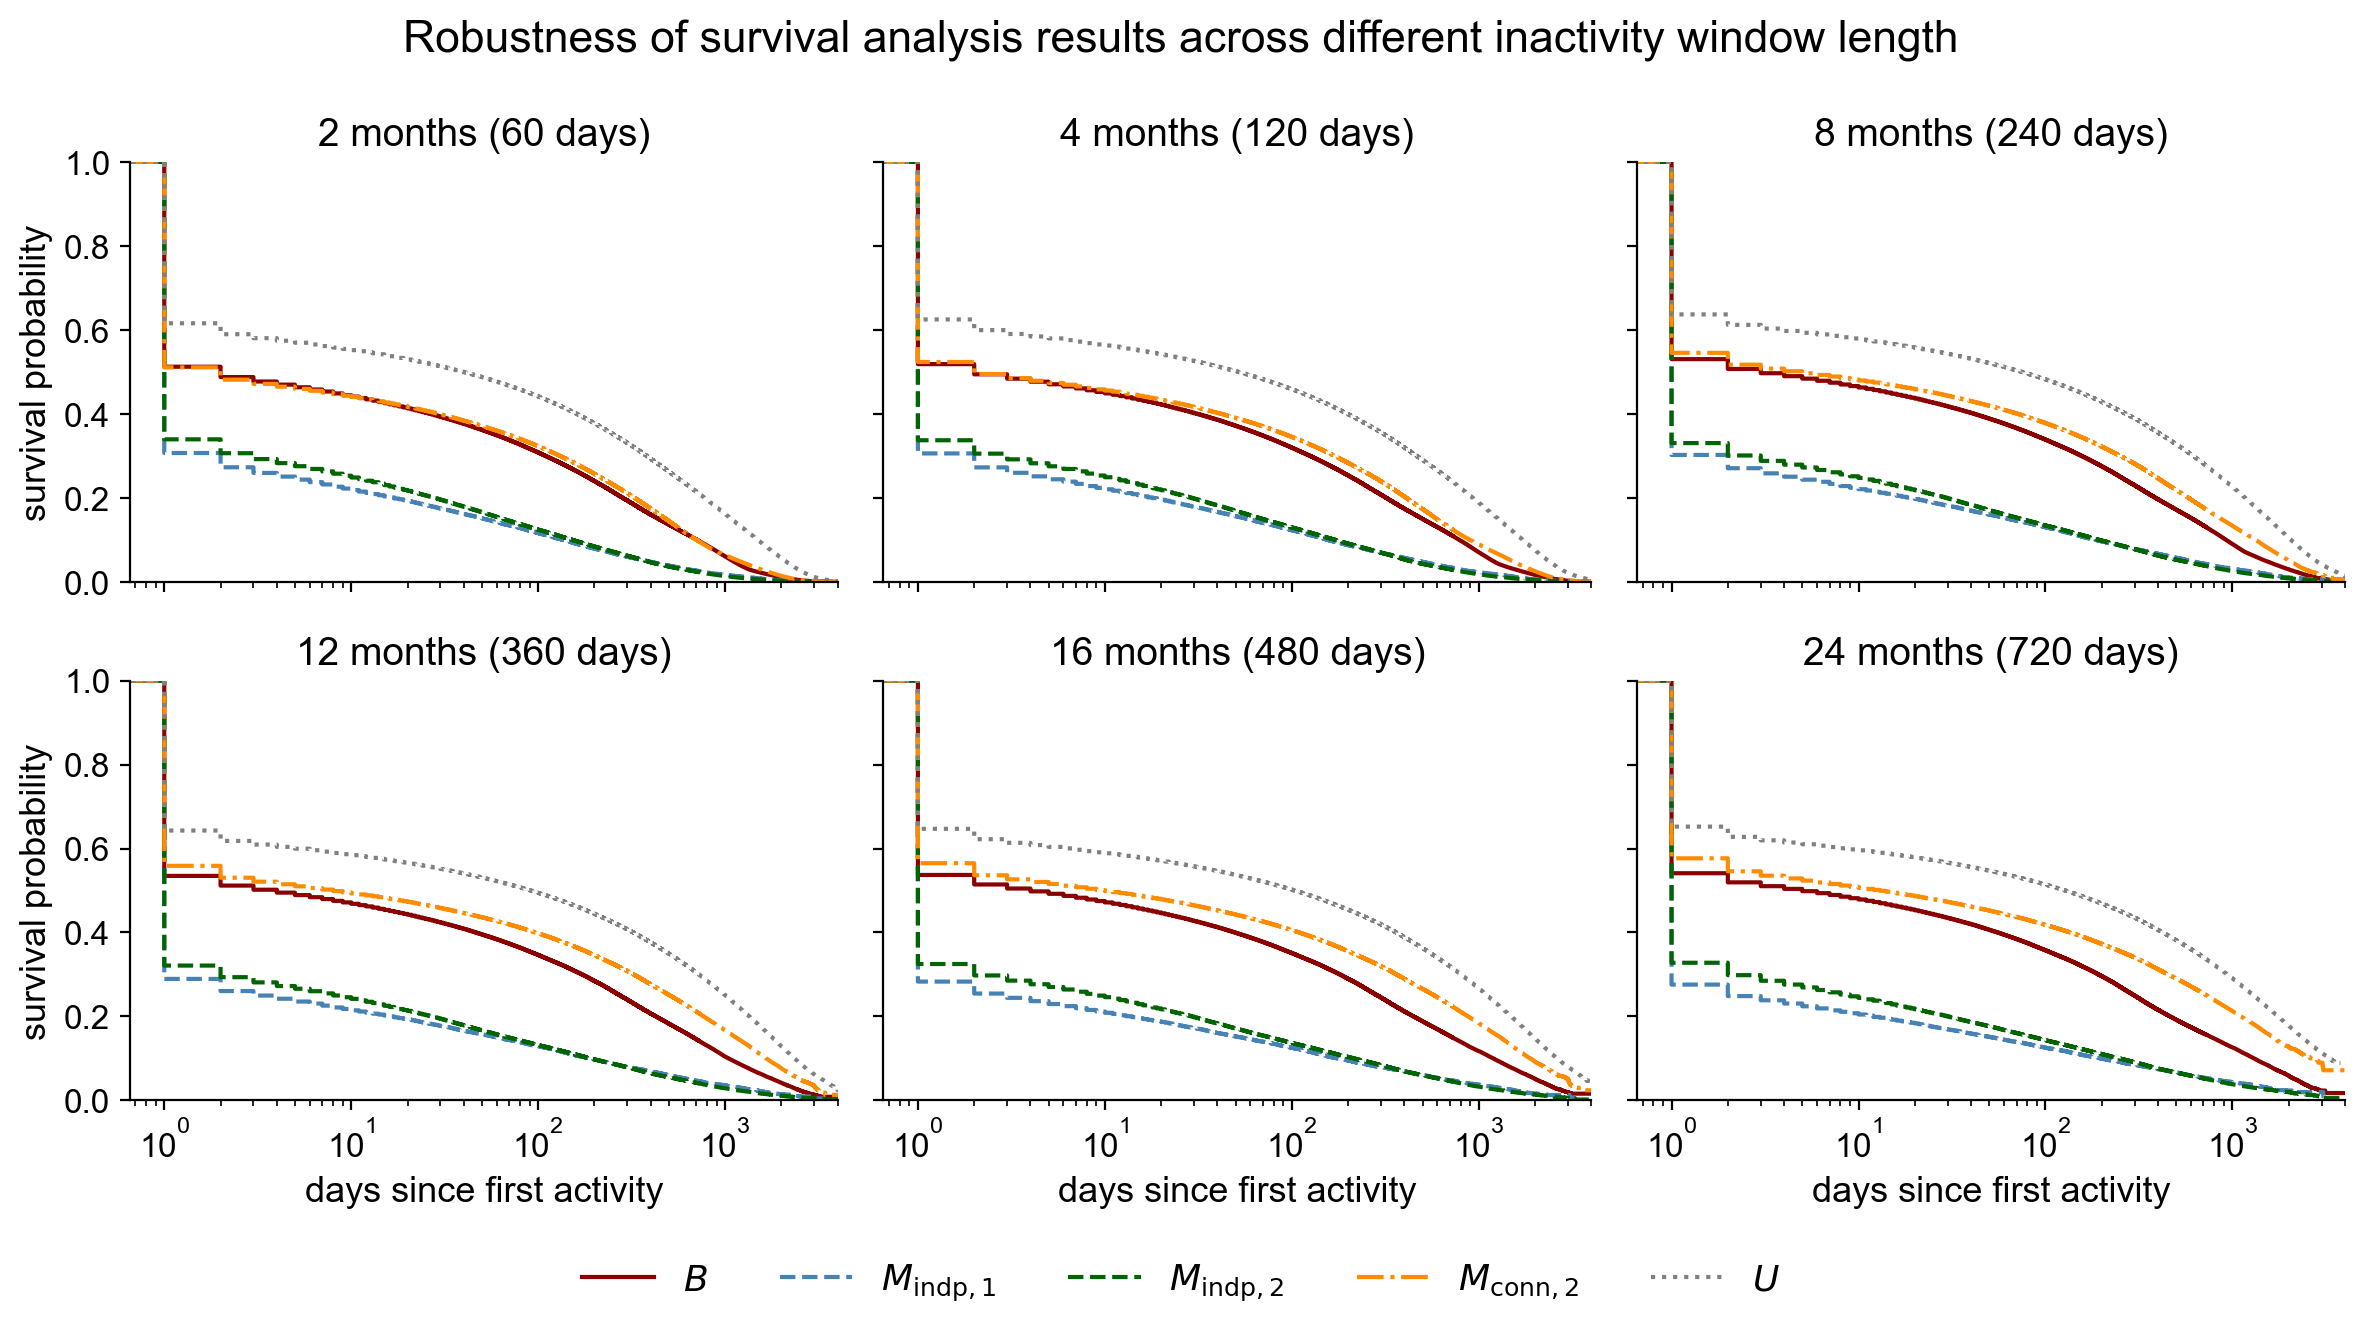

In [27]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(12,7),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()

for ax, tau in zip(axes, TAU_VALUES):

    for name in cohorts:
        key = (tau, name)

        if key not in robustness_kmfs:
            continue

        robustness_kmfs[key].plot_survival_function(
            ax=ax,
            ci_show=False,
            **styles[name],
        )

    ax.set_xscale("log")
    ax.set_xlim(0, 4000)
    ax.set_ylim(0, 1)

    ax.set_title(
        f"{TAU_LABELS[tau]} ({tau} days)",
        fontsize=14,
    )

    ax.set_xlabel("days since first activity", fontsize=13)
    ax.set_ylabel("survival probability", fontsize=13)

    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Hide the unused sixth panel
# axes[-1].set_visible(False)

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=5,
    frameon=False,
    fontsize=13,
)

fig.suptitle(
    "Robustness of survival analysis results across different inactivity window length",
    fontsize=16,
    y=0.95,
)

plt.tight_layout(rect=[0, 0.07, 1, 0.96])

# plt.savefig("../../output/appendix/survival_curves_5sets_varying_tau.pdf", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/appendix/survival_curves_5sets_varying_tau.png", dpi=300, bbox_inches="tight")

## [optional: skipped!] slice for users with different engagement levels

In [28]:
LOYALTY_BINS   = [0.0, 0.25, 0.5, 0.75, 1.0]
LOYALTY_LABELS = ["(0, .25]", "(.25, .5]", "(.5, .75]", "(.75, 1]"]

def compute_loyalty(user_subr, subr_set, user_total):
    n_in = (user_subr
            .filter(pl.col("subreddit").is_in(list(subr_set)))
            .group_by("author")
            .agg(pl.col("n_posts").sum().alias("n_in")))
    return (n_in.join(user_total.select(["author", "n_total"]), on="author")
                .with_columns((pl.col("n_in") / pl.col("n_total")).alias("loyalty"))
                .select(["author", "loyalty"]))

# note: build_survival_table's "within" branch can now take user_subr instead of
# count_df_post — same logic, much smaller input

SCOPE = "within"   # see note below

results = {}   # results[(cohort, bin)] = (kmf, table)
for name, subrs in cohorts.items():
    print(name)
    t = build_survival_table(user_subr, subrs, scope=SCOPE,
                             user_span_platform=user_span_platform)
    loy = compute_loyalty(user_subr, subrs, user_total).to_pandas()
    t = t.merge(loy, on="author", how="left")
    t["loyalty_bin"] = pd.cut(t["loyalty"], bins=LOYALTY_BINS,
                              labels=LOYALTY_LABELS, include_lowest=True)

    for lab in LOYALTY_LABELS:
        sub = t[t["loyalty_bin"] == lab]
        if len(sub) < 100:      # skip unstable strata
            continue
        kmf = KaplanMeierFitter(label=f"{name} | {lab}")
        kmf.fit(durations=sub["tenure_exit"], event_observed=sub["event"],
                entry=sub["tenure_entry"])
        results[(name, lab)] = (kmf, sub)

banned


matched1_indp
matched2_indp
matched2_conn
random


/tmp/ipykernel_1057610/2003038439.py:19: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 2000)
/tmp/ipykernel_1057610/2003038439.py:19: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 2000)
/tmp/ipykernel_1057610/2003038439.py:19: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 2000)
/tmp/ipykernel_1057610/2003038439.py:19: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 2000)


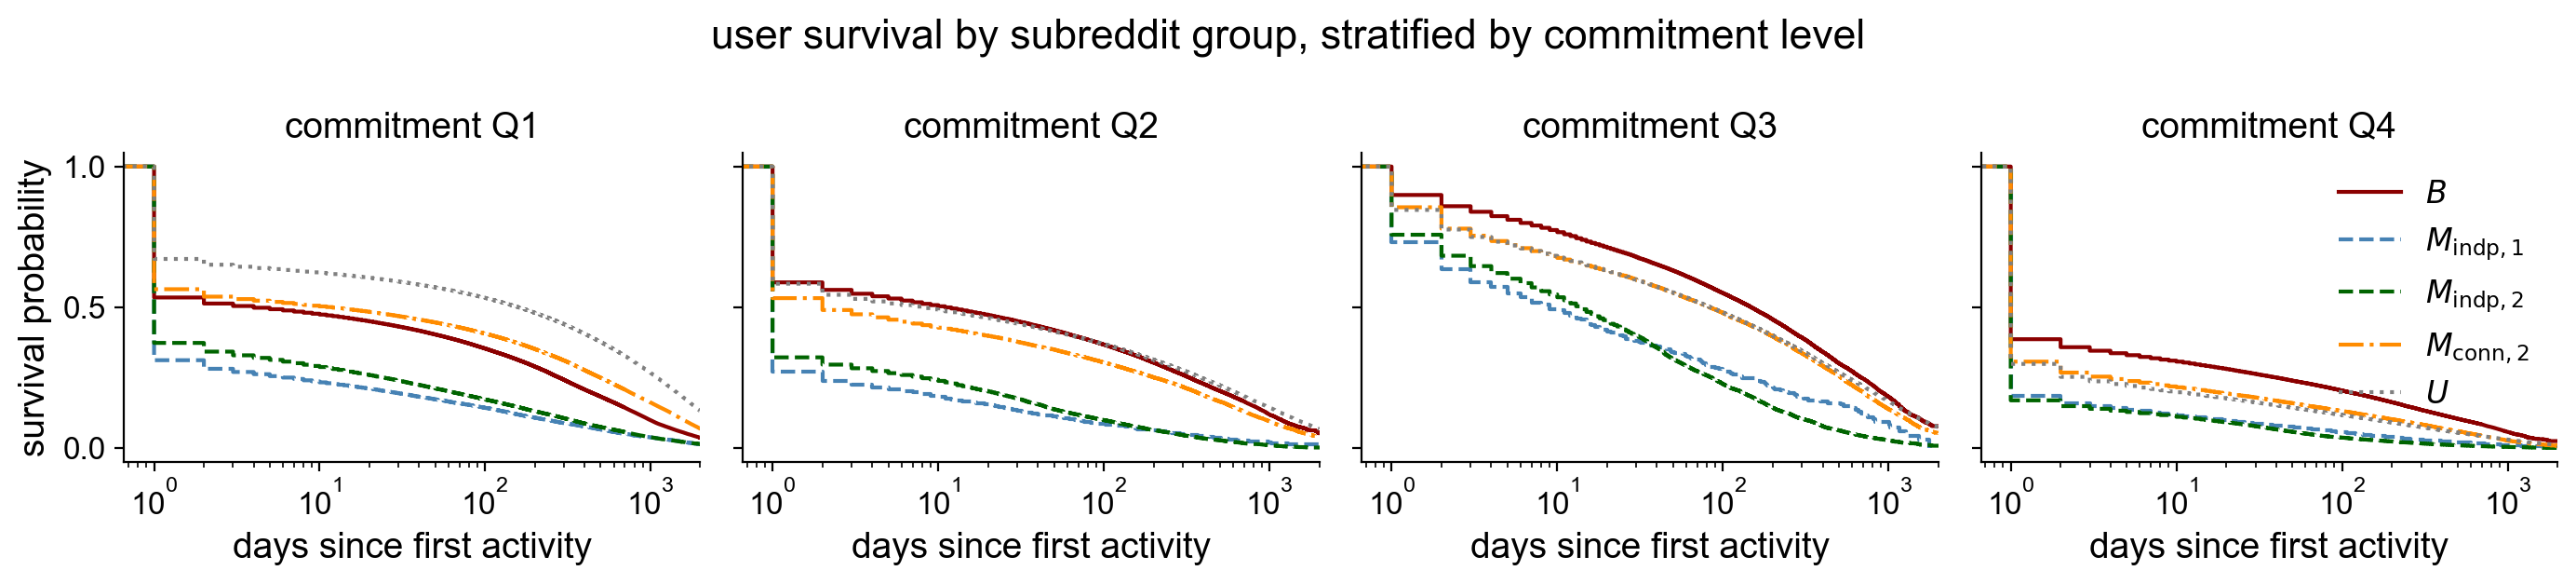

In [29]:
styles = {
    "banned":        dict(color="darkred",   linestyle="-", label=r"$B$"),
    "matched1_indp": dict(color="steelblue", linestyle="--", label=r"$M_{\mathrm{indp},1}$"),
    "matched2_indp": dict(color="darkgreen", linestyle="--", label=r"$M_{\mathrm{indp},2}$"),
    "matched2_conn": dict(color="darkorange",linestyle="-.", label=r"$M_{\mathrm{conn},2}$"),
    "random":        dict(color="grey",      linestyle=":", label=r"$U$"),
}

fig, axes = plt.subplots(1, len(LOYALTY_LABELS),
                         figsize=(3.5*len(LOYALTY_LABELS), 3.2), sharey=True)

for ax, lab in zip(axes, LOYALTY_LABELS):
    for name in cohorts:
        if (name, lab) not in results:   # skipped strata (e.g., n < 100)
            continue
        kmf, _ = results[(name, lab)]
        kmf.plot_survival_function(ax=ax, ci_show=False, **styles[name])
    ax.set_xscale("log")
    ax.set_xlim(0, 2000)
    # ax.xaxis.set_major_locator(FixedLocator([300, 1000, 3000]))
    # ax.xaxis.set_major_formatter(ScalarFormatter())
    # ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("days since first activity", fontsize=14)
    if ax is axes[0]:
        ax.set_ylabel("survival probability", fontsize=14)
    ax.get_legend().remove() if ax.get_legend() else None

for i in range(len(axes)):
    axes[i].set_title(f"commitment Q{i+1}", fontsize=14)
axes[-1].legend(fontsize=12, frameon=False, loc=1)

fig.suptitle("user survival by subreddit group, stratified by commitment level", fontsize=16, y=0.98)
plt.tight_layout()
plt.savefig("../../output/appendix/survival_curves_5cohorts_by_commitment_strata.pdf", dpi=300, bbox_inches="tight")
plt.savefig("../../output/appendix/survival_curves_5cohorts_by_commitment_strata.png", dpi=300, bbox_inches="tight")

## appendix: subreddits by year of first submission

In [30]:
from src.utils.data_loader_polars import load_filtered_data

years = range(2006, 2021)
input_fpath = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020"
df = load_filtered_data(years=years, data_dir=input_fpath, filetype="submissions", filter_bots=False)

******************
Loading Submissions from /cinddata/reddit-ban-study/filtered-data/submissions/subm-from-subr-banned-2020...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019
	loading: 2020


In [31]:
df_aggr = df.with_columns(
    pl.col("created_utc").dt.year().alias("year")
).group_by("subreddit").agg(
    pl.col("year").min().alias("min_year")).to_pandas()

df_aggr_by_year = df_aggr.groupby("min_year").agg({"subreddit":"nunique"}).reset_index()
df_aggr_by_year

,min_year,subreddit
0,2006,1
1,2008,8
2,2009,26
3,2010,30
4,2011,37
5,2012,133
6,2013,195
7,2014,196
8,2015,241
9,2016,281


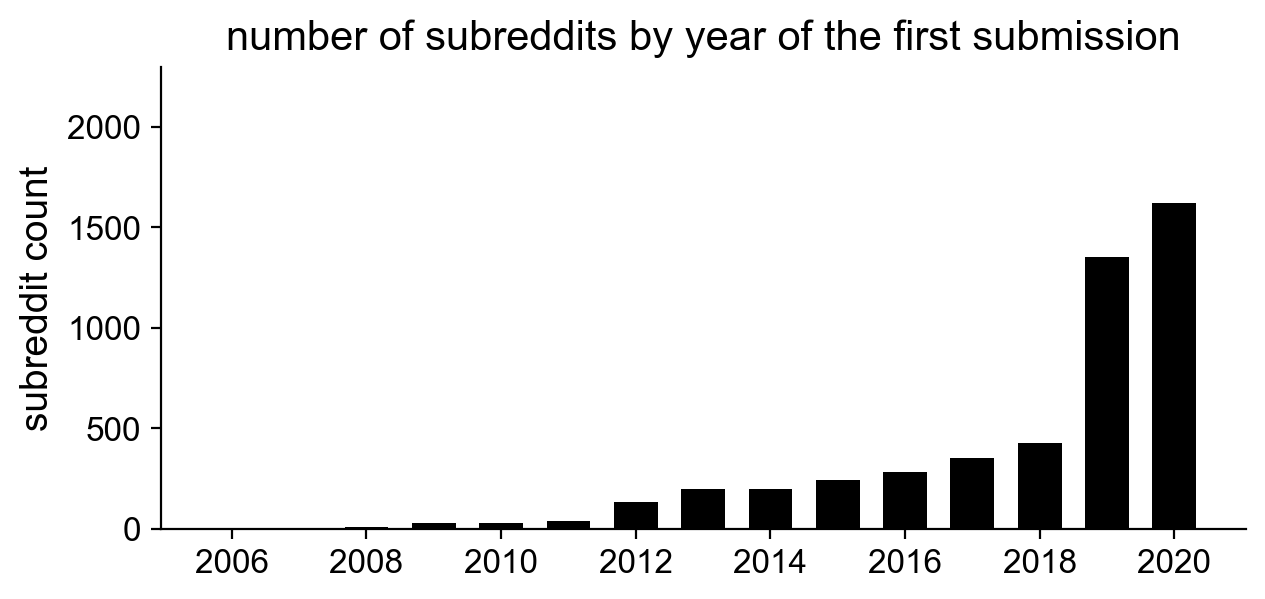

In [32]:
fig,ax = plt.subplots(figsize=(7,3))
bars = ax.bar(df_aggr_by_year["min_year"], df_aggr_by_year["subreddit"], color="black", width=.65)
ax.set_ylim(0,2300)
# ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_ylabel("subreddit count", fontsize=14)
ax.set_title("number of subreddits by year of the first submission", fontsize=15)
plt.savefig("../../output/appendix/n_subr_min_year.pdf", dpi=300, bbox_inches="tight")
plt.savefig("../../output/appendix/n_subr_min_year.png", dpi=300, bbox_inches="tight")